## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid")

## 2. Load and inspect the data

In [2]:
df = pd.read_csv("housing.csv")


In [3]:
df.shape

(20640, 10)

In [21]:
df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [22]:
df.tail()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND
20639,-121.24,39.37,16.0,2785.0,616.0,1387.0,530.0,2.3886,89400.0,INLAND


In [23]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [24]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [25]:
df.isnull().sum()


longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

## 3. Exploratory Data Analysis

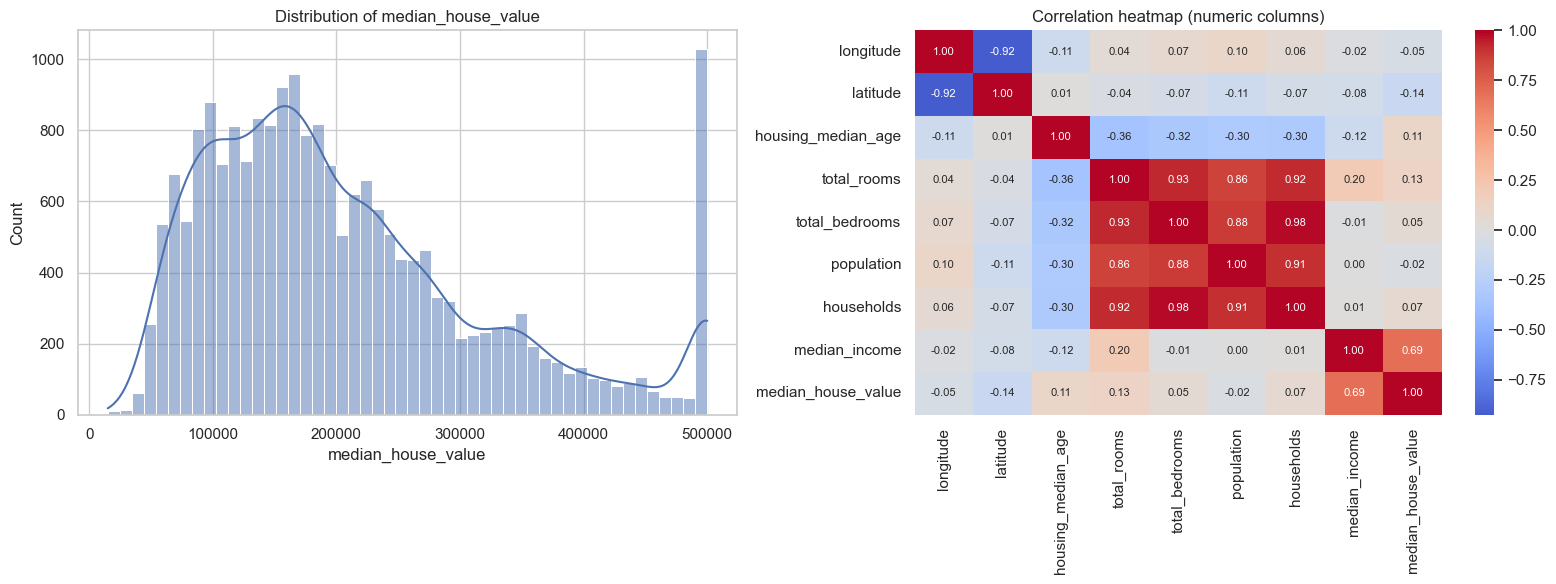

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.histplot(df["median_house_value"], bins=50, kde=True, ax=axes[0])
axes[0].set_title("Distribution of median_house_value")

num_cols = df.select_dtypes(include="number").columns
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=axes[1], annot_kws={"size": 8})
axes[1].set_title("Correlation heatmap (numeric columns)")

plt.tight_layout()
plt.show()

## 4. Feature engineering

In [27]:
data = df.copy()

data["rooms_per_household"] = data["total_rooms"] / data["households"]
data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"]
data["population_per_household"] = data["population"] / data["households"]
data["income_x_age"] = data["median_income"] * data["housing_median_age"]
data["income_x_rooms"] = data["median_income"] * data["rooms_per_household"]

data[["rooms_per_household", "bedrooms_per_room", "population_per_household",
      "income_x_age", "income_x_rooms"]].describe().T

,count,mean,std,min,25%,50%,75%,max
rooms_per_household,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
bedrooms_per_room,20433.0,0.213039,0.057983,0.100000,0.175427,0.203162,0.239821,1.000000
population_per_household,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
income_x_age,20640.0,108.008027,74.386418,1.625000,57.997425,92.502950,140.104900,780.005200
income_x_rooms,20640.0,22.550365,17.923133,0.856971,11.686844,18.021764,27.864426,612.966667


## 5. Handle multicollinearity

In [28]:
def compute_vif(frame):
    frame = frame.dropna()
    out = {}
    for col in frame.columns:
        others = frame.drop(columns=col)
        r2 = LinearRegression().fit(others, frame[col]).score(others, frame[col])
        out[col] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False).round(2)

raw_features = ["longitude", "latitude", "housing_median_age", "total_rooms",
                "total_bedrooms", "population", "households", "median_income"]

print("VIF BEFORE (raw columns):")
display(compute_vif(df[raw_features]).to_frame("VIF"))

VIF BEFORE (raw columns):


,VIF
total_bedrooms,36.00
households,35.14
total_rooms,12.72
latitude,8.83
longitude,8.71
population,6.37
median_income,1.73
housing_median_age,1.26


In [29]:
count_cols = ["total_rooms", "total_bedrooms", "population", "households"]
data = data.drop(columns=count_cols)

base_features = ["longitude", "latitude", "housing_median_age", "median_income",
                 "rooms_per_household", "bedrooms_per_room", "population_per_household"]
print("\nMissing values:\n", df.isnull().sum())
display(df.describe().T)
display(compute_vif(data[base_features]).to_frame("VIF"))


Missing values:
 longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


,VIF
latitude,9.17
longitude,8.88
median_income,1.98
bedrooms_per_room,1.87
rooms_per_household,1.31
housing_median_age,1.11
population_per_household,1.00


## 6. Encode the categorical column

In [30]:
data = pd.get_dummies(data, columns=["ocean_proximity"], drop_first=True, dtype=float)
print(data.shape)
data.columns.tolist()

(20640, 14)


['longitude',
 'latitude',
 'housing_median_age',
 'median_income',
 'median_house_value',
 'rooms_per_household',
 'bedrooms_per_room',
 'population_per_household',
 'income_x_age',
 'income_x_rooms',
 'ocean_proximity_INLAND',
 'ocean_proximity_ISLAND',
 'ocean_proximity_NEAR BAY',
 'ocean_proximity_NEAR OCEAN']

## 7. Train/test split (80/20)

In [31]:
X = data.drop(columns="median_house_value")
y = data["median_house_value"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Missing values left in X_train:", int(X_train.isnull().sum().sum()), "(the pipeline will impute these)")

Train: (16512, 13)  Test: (4128, 13)
Missing values left in X_train: 0 (the pipeline will impute these)


## 8. Build the pipelines

In [34]:
def make_pipe(model):
    return Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("model", model),
    ])


ols = make_pipe(LinearRegression()).fit(X_train, y_train)

alphas = np.logspace(-3, 4, 15)
ridge_cv = GridSearchCV(make_pipe(Ridge()), {"model__alpha": alphas},
                        cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
ridge_cv.fit(X_train, y_train)
lasso_cv = GridSearchCV(make_pipe(Lasso(max_iter=50000)), {"model__alpha": alphas},
                        cv=5, scoring="neg_root_mean_squared_error", n_jobs=-1)
lasso_cv.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_cv.best_params_["model__alpha"])
print("Best Lasso alpha:", lasso_cv.best_params_["model__alpha"])

Best Ridge alpha: 10.0
Best Lasso alpha: 31.622776601683793


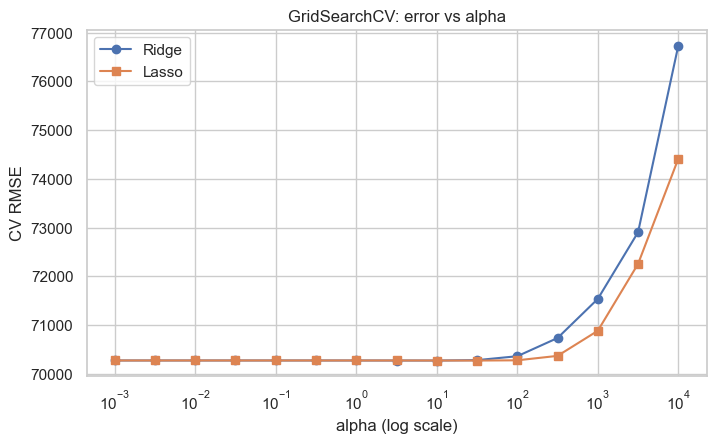

In [35]:
plt.figure(figsize=(8, 4.5))
plt.semilogx(alphas, -ridge_cv.cv_results_["mean_test_score"], marker="o", label="Ridge")
plt.semilogx(alphas, -lasso_cv.cv_results_["mean_test_score"], marker="s", label="Lasso")
plt.xlabel("alpha (log scale)")
plt.ylabel("CV RMSE")
plt.title("GridSearchCV: error vs alpha")
plt.legend()
plt.show()

## 9. Compare the models (RMSE, MAE, R²)

In [36]:
models = {
    "OLS": ols,
    "Ridge (L2)": ridge_cv.best_estimator_,
    "Lasso (L1)": lasso_cv.best_estimator_,
}

rows, preds = [], {}
for name, m in models.items():
    p = m.predict(X_test)
    preds[name] = p
    rows.append({
        "Model": name,
        "Test RMSE": np.sqrt(mean_squared_error(y_test, p)),
        "Test MAE": mean_absolute_error(y_test, p),
        "Test R2": r2_score(y_test, p),
        "Train R2": r2_score(y_train, m.predict(X_train)),
    })

results = pd.DataFrame(rows).set_index("Model")
display(results.round(4))

,Test RMSE,Test MAE,Test R2,Train R2
Model,,,,
OLS,71557.8058,51254.6673,0.6092,0.6314
Ridge (L2),71561.7906,51232.6198,0.6092,0.6314
Lasso (L1),71565.2718,51236.1547,0.6092,0.6314


## 10. Predicted vs actual

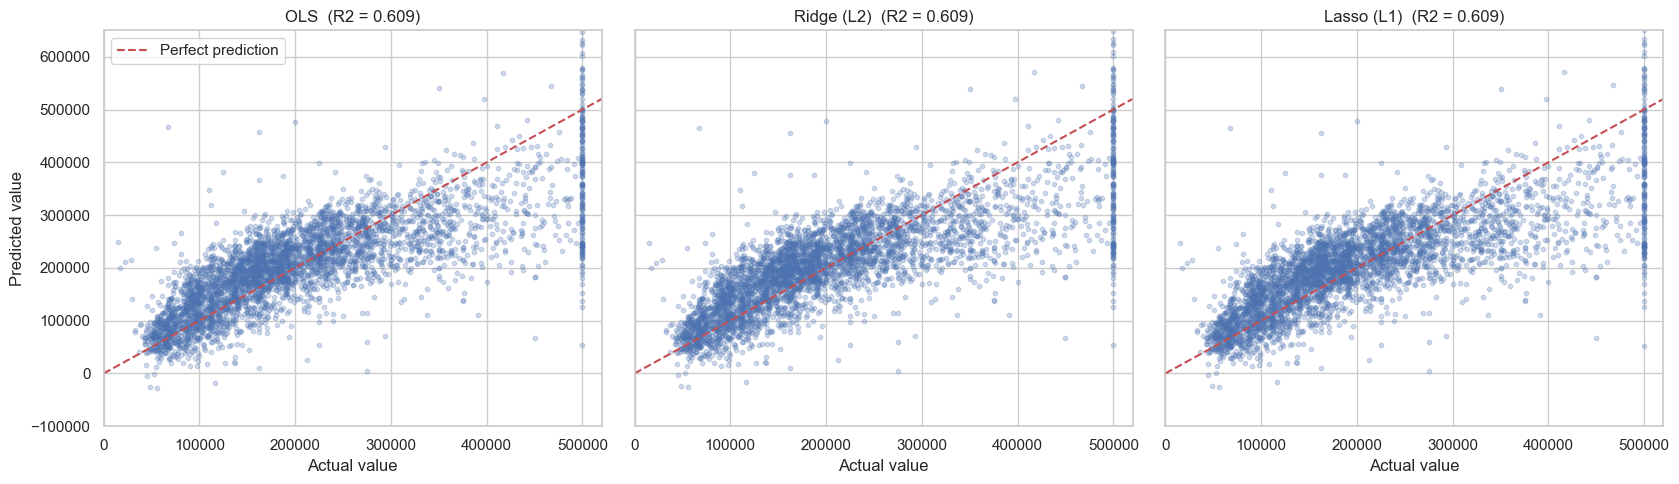

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
lims = [0, 520000]

for ax, (name, p) in zip(axes, preds.items()):
    ax.scatter(y_test, p, alpha=0.25, s=10)
    ax.plot(lims, lims, "r--", label="Perfect prediction")
    ax.set_title(f"{name}  (R2 = {r2_score(y_test, p):.3f})")
    ax.set_xlabel("Actual value")
    ax.set_xlim(lims); ax.set_ylim(-100000, 650000)
axes[0].set_ylabel("Predicted value")
axes[0].legend()
plt.tight_layout()
plt.show()

## 11. Residual analysis

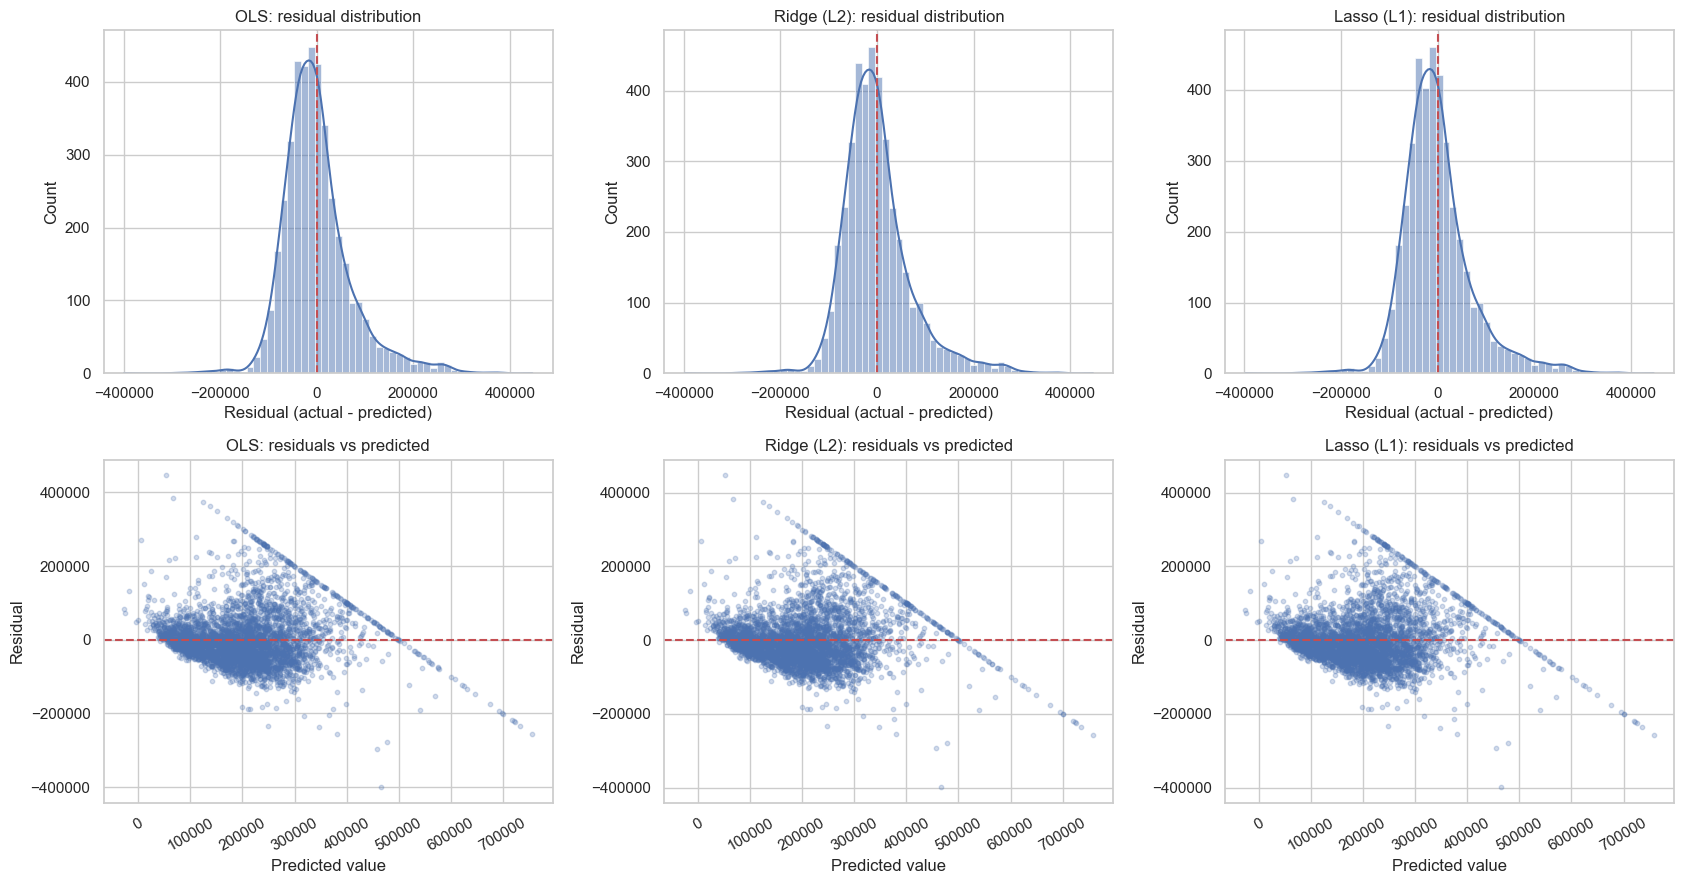

Mean residual / std of residual:
  OLS          mean =     673.72   std =   71563.30
  Ridge (L2)   mean =     662.25   std =   71567.40
  Lasso (L1)   mean =     663.79   std =   71570.86


In [38]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))

for i, (name, p) in enumerate(preds.items()):
    resid = y_test - p

    sns.histplot(resid, bins=60, kde=True, ax=axes[0, i])
    axes[0, i].axvline(0, color="r", linestyle="--")
    axes[0, i].set_title(f"{name}: residual distribution")
    axes[0, i].set_xlabel("Residual (actual - predicted)")

    axes[1, i].scatter(p, resid, alpha=0.25, s=10)
    axes[1, i].axhline(0, color="r", linestyle="--")
    axes[1, i].set_title(f"{name}: residuals vs predicted")
    axes[1, i].set_xlabel("Predicted value")
    axes[1, i].set_ylabel("Residual")
    axes[1, i].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print("Mean residual / std of residual:")
for name, p in preds.items():
    r = y_test - p
    print(f"  {name:12s} mean = {r.mean():10.2f}   std = {r.std():10.2f}")

## 12. Coefficients: what did regularization do?

,OLS,Ridge,Lasso
longitude,-53339.0,-52362.0,-52468.0
latitude,-52325.0,-51303.0,-51400.0
housing_median_age,2203.0,1976.0,2051.0
median_income,89108.0,87951.0,87938.0
rooms_per_household,17204.0,16706.0,16589.0
bedrooms_per_room,21050.0,20881.0,20857.0
population_per_household,-4350.0,-4337.0,-4306.0
income_x_age,13472.0,13807.0,13661.0
income_x_rooms,-21666.0,-20619.0,-20435.0
ocean_proximity_INLAND,-15980.0,-16322.0,-16292.0


Features Lasso set to exactly zero: []


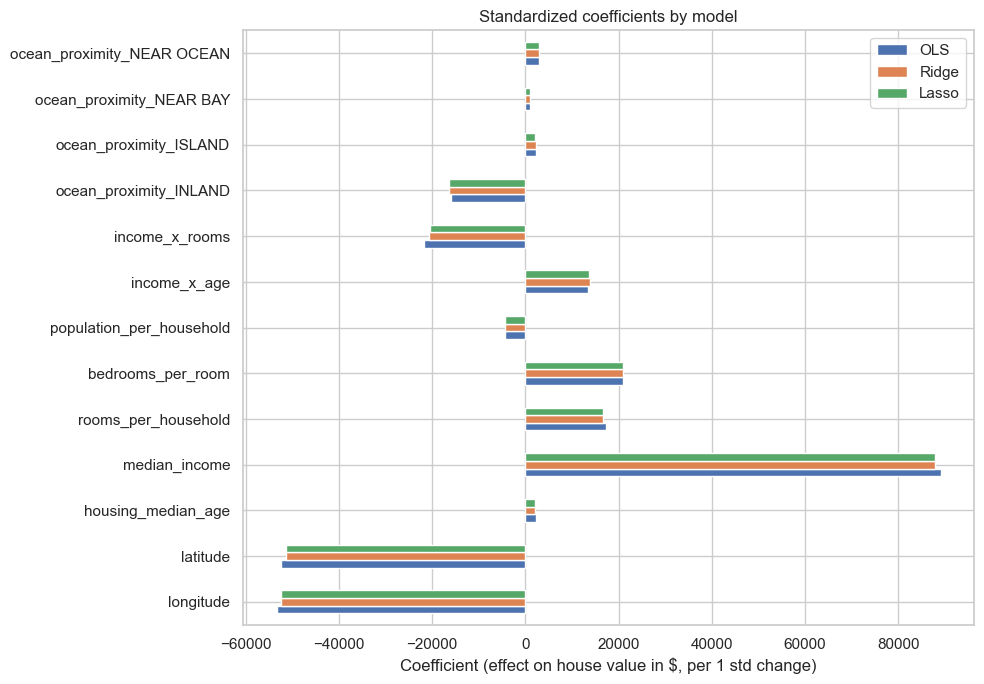

In [39]:
coef_df = pd.DataFrame({
    "OLS": ols.named_steps["model"].coef_,
    "Ridge": ridge_cv.best_estimator_.named_steps["model"].coef_,
    "Lasso": lasso_cv.best_estimator_.named_steps["model"].coef_,
}, index=X.columns)

display(coef_df.round(0))
print("Features Lasso set to exactly zero:", coef_df.index[coef_df["Lasso"] == 0].tolist())

coef_df.plot(kind="barh", figsize=(10, 7))
plt.title("Standardized coefficients by model")
plt.xlabel("Coefficient (effect on house value in $, per 1 std change)")
plt.tight_layout()
plt.show()